# Placental stress → maternal-side (decidual) response, using paired tissues from the same pregnancy (Addendum G)

Addendum G was committed before this notebook was run. Single cohort (GSE203507), exploratory.

- **G1 (primary):** does a donor's villous hypoxia score carry information about *the same donor's*
  decidual inflammatory response, beyond group membership and trophoblast contamination? (within-group permutation)
- **G2 (secondary, underpowered):** at similar villous stress, is the decidual response higher in PE than FGR-only?
- **G3:** angiogenesis response score; leave-one-donor-out.

In [1]:
import os, sys, warnings
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); EXT = ROOT / "data_external"
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(EXT / "h.all.v2024.1.Hs.symbols.gmt")}
HYP = set(gmt["HALLMARK_HYPOXIA"])
RESP = (set(gmt["HALLMARK_TNFA_SIGNALING_VIA_NFKB"]) | set(gmt["HALLMARK_INFLAMMATORY_RESPONSE"])) - HYP
ANG = set(gmt["HALLMARK_ANGIOGENESIS"]) - HYP
assert not (RESP & HYP) and not (ANG & HYP)

def vst_of(counts, groups):
    counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
    md = pd.DataFrame({"g": groups}, index=counts.columns)
    dds = DeseqDataSet(counts=counts.T.astype(int), metadata=md, design="~g", inference=DefaultInference(n_cpus=4), quiet=True)
    dds.fit_size_factors(); dds.vst(use_design=False)
    return pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)
def setscore(vst, genes):
    z = (vst - vst.mean()) / vst.std(); g = sorted(x for x in genes if x in z.columns); return z[g].mean(axis=1), len(g)

cv = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
mv = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[cv.columns]
cd = pd.read_csv(DATA_DIR / "extension" / "decidua" / "track01_counts_db.csv", index_col=0)
md = pd.read_csv(DATA_DIR / "extension" / "decidua" / "track01_metadata_db.csv", index_col=0).loc[cd.columns]
vst_v = vst_of(cv, mv.pe_status.values); vst_db = vst_of(cd, md.pe_status.values)

markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
TROPH = set(markers.loc[markers.cell_class.isin(["villous_cytotrophoblast", "syncytiotrophoblast", "extravillous_trophoblast"]), "gene_symbol"])

stress, n1 = setscore(vst_v, HYP)
resp, n2 = setscore(vst_db, RESP); ang, n3 = setscore(vst_db, ANG); troph, n4 = setscore(vst_db, TROPH)
print(f"Genes used: villous hypoxia {n1}, decidual inflammatory {n2}, decidual angiogenesis {n3}, decidual trophoblast markers {n4}")
P = pd.DataFrame({"donor_id": mv.donor_id, "group": mv.group, "ga": mv.ga_delivery_weeks, "stress": stress.values}, index=mv.index)
P = P.merge(pd.DataFrame({"donor_id": md.donor_id, "resp": resp.values, "ang": ang.values, "troph": troph.values}), on="donor_id")
print(P.group.value_counts().to_dict())
print(f"Decidual inflammatory score vs decidual trophoblast content: Spearman rho = {stats.spearmanr(P.resp, P.troph)[0]:.2f}")

Genes used: villous hypoxia 177, decidual inflammatory 292, decidual angiogenesis 29, decidual trophoblast markers 12
{'EOPE': 8, 'FGR': 5, 'iPTB': 5, 'TB': 5, 'EOPE+FGR': 4}
Decidual inflammatory score vs decidual trophoblast content: Spearman rho = 0.05


## G1 (primary): within-group permutation of donor pairs

In [2]:
def coupling_stat(df, y):
    d = df.copy()
    d["s_c"] = d.stress - d.groupby("group").stress.transform("mean")
    d["y_c"] = d[y] - d.groupby("group")[y].transform("mean")
    d["t_c"] = d.troph - d.groupby("group").troph.transform("mean")
    b = np.polyfit(d.t_c, d.y_c, 1); d["y_r"] = d.y_c - np.polyval(b, d.t_c)
    return stats.spearmanr(d.s_c, d.y_r)[0]

pre = P[P.group != "TB"].reset_index(drop=True)
rng = np.random.default_rng(42)
g1 = []
for y in ["resp", "ang"]:
    obs = coupling_stat(pre, y)
    null = np.empty(10000)
    for i in range(10000):
        perm = pre.copy()
        for g, idx in perm.groupby("group").groups.items():
            idx = np.array(list(idx)); sh = rng.permutation(idx)
            perm.loc[idx, [y, "troph"]] = pre.loc[sh, [y, "troph"]].values  # decidua sample moves as a unit
        null[i] = coupling_stat(perm, y)
    loo = [coupling_stat(pre.drop(index=j), y) for j in pre.index]
    g1.append({"response": {"resp": "inflammatory (primary)", "ang": "angiogenesis (secondary)"}[y], "n_pairs": len(pre),
               "rho_obs": obs, "null_median": np.median(null), "null_95th": np.quantile(null, .95),
               "p_one_sided": (1 + (null >= obs).sum()) / 10001, "loo_min": min(loo), "loo_max": max(loo)})
    if y == "resp": null_resp, obs_resp = null, obs
g1 = pd.DataFrame(g1); g1.to_csv(RES_DIR / "G1_pair_coupling.csv", index=False)
pd.set_option("display.width", 200); print(g1.round(4).to_string(index=False))
print("Cross-tissue coupling claimed (primary p < 0.05):", bool(g1.p_one_sided.iloc[0] < 0.05))

                response  n_pairs  rho_obs  null_median  null_95th  p_one_sided  loo_min  loo_max
  inflammatory (primary)       22  -0.0514       0.0107     0.3665       0.6126  -0.1532   0.0779
angiogenesis (secondary)       22  -0.4094       0.0085     0.3834       0.9711  -0.5221  -0.3052
Cross-tissue coupling claimed (primary p < 0.05): False


## G2 (secondary, underpowered): PE vs FGR-only decidual response at similar villous stress

In [3]:
pf = P[P.group.isin(["EOPE", "EOPE+FGR", "FGR"])].copy(); pf["PE"] = (pf.group != "FGR").astype(int)
rng_pe = (pf.loc[pf.PE == 1, "stress"].min(), pf.loc[pf.PE == 1, "stress"].max())
rng_fg = (pf.loc[pf.PE == 0, "stress"].min(), pf.loc[pf.PE == 0, "stress"].max())
overlap = (max(rng_pe[0], rng_fg[0]), min(rng_pe[1], rng_fg[1]))
n_support = int(((pf.stress >= overlap[0]) & (pf.stress <= overlap[1])).sum())
print(f"Villous stress range PE {np.round(rng_pe, 2)}, FGR-only {np.round(rng_fg, 2)}; overlap {np.round(overlap, 2)} contains {n_support}/{len(pf)} pairs")
g2 = []
for y in ["resp", "ang"]:
    f = smf.ols(f"{y} ~ PE + stress + troph + ga", data=pf).fit()
    g2.append({"response": y, "n_PE": int(pf.PE.sum()), "n_FGR": int((1 - pf.PE).sum()), "PE_coef": f.params["PE"],
               "CI_low": f.conf_int().loc["PE", 0], "CI_high": f.conf_int().loc["PE", 1], "p": f.pvalues["PE"],
               "stress_coef": f.params["stress"], "stress_p": f.pvalues["stress"]})
g2 = pd.DataFrame(g2); g2.to_csv(RES_DIR / "G2_PE_vs_FGR_decidua.csv", index=False); print(g2.round(3).to_string(index=False))

Villous stress range PE [-0.13  0.85], FGR-only [-0.3   0.01]; overlap [-0.13  0.01] contains 6/17 pairs
response  n_PE  n_FGR  PE_coef  CI_low  CI_high     p  stress_coef  stress_p
    resp    12      5   -0.114  -0.474    0.245 0.502       -0.049     0.856
     ang    12      5    0.064  -0.226    0.354 0.640       -0.063     0.771


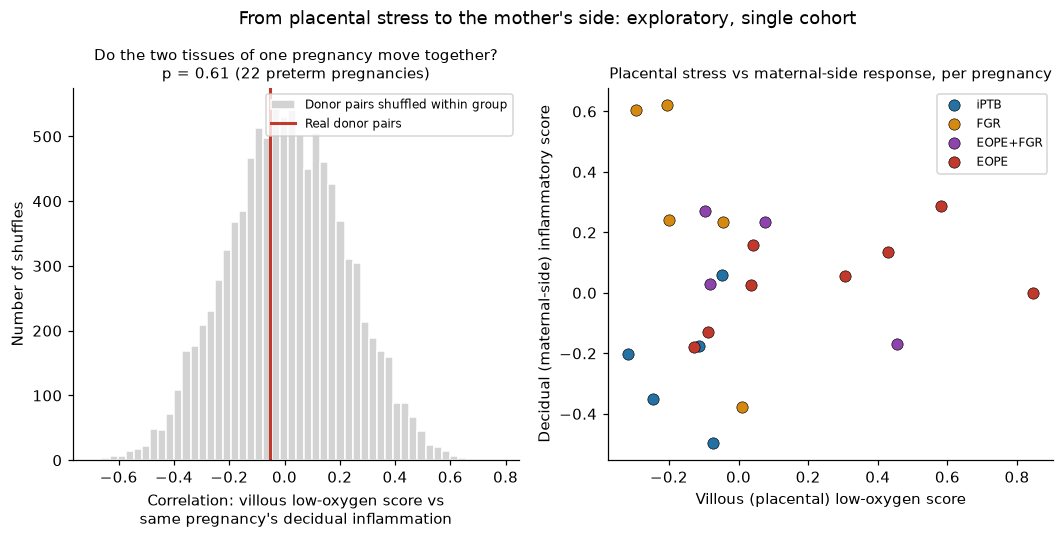

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axes[0]
ax.hist(null_resp, bins=50, color="lightgrey", edgecolor="white", label="Donor pairs shuffled within group")
ax.axvline(obs_resp, c="#c0392b", lw=2, label="Real donor pairs")
ax.set_xlabel("Correlation: villous low-oxygen score vs\nsame pregnancy's decidual inflammation"); ax.set_ylabel("Number of shuffles")
ax.set_title(f"Do the two tissues of one pregnancy move together?\np = {g1.p_one_sided.iloc[0]:.2f} (22 preterm pregnancies)", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
col = {"iPTB": "#2471a3", "FGR": "#d68910", "EOPE+FGR": "#8e44ad", "EOPE": "#c0392b"}
for g, cc in col.items():
    m = P.group == g; ax.scatter(P.stress[m], P.resp[m], c=cc, s=55, edgecolor="k", lw=0.4, label=g)
ax.set_xlabel("Villous (placental) low-oxygen score"); ax.set_ylabel("Decidual (maternal-side) inflammatory score")
ax.set_title("Placental stress vs maternal-side response, per pregnancy", fontsize=10); ax.legend(fontsize=8)
fig.suptitle("From placental stress to the mother's side: exploratory, single cohort", y=1.04)
plt.savefig(FIG_DIR / "fig13_villous_to_decidua.png", dpi=300, bbox_inches="tight"); plt.show()